# 0.0 Imports

In [70]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import inflection

from sklearn.feature_selection import VarianceThreshold
from boruta import BorutaPy

## 0.1 Helper Functions

## 0.2 Loading data

### 0.2.1 Data Train

In [5]:
df_raw = pd.read_csv('dataset/train.csv')

In [6]:
df_raw.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


### 0.2.2 Data Test

In [7]:
df_test = pd.read_csv('dataset/test.csv')

# 1.0 DESCRICAO DOS DADOS

In [98]:
df1 = df_raw.copy()

In [99]:
df1.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='str')

## 1.1 Rename columns

In [100]:

cols_old = [['id', 'Age', 'Flight Distance', 'Inflight wifi service',
             'Departure/Arrival time convenient', 'Ease of Online booking',
             'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 
             'Inflight entertainment', 'On-board service', 'Leg room service', 
             'Baggage handling', 'Checkin service', 'Cleanliness',
             'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
             'Customer Type', 'Type of Travel', 'Class', 'satisfaction']]

snakecase = lambda x: inflection.underscore( x.replace(" ", "_").replace("/", "_") )
cols_new = list(map(snakecase, cols_old[0]))

#rename
df1.columns = cols_new

In [101]:
cols_new

['id',
 'age',
 'flight_distance',
 'inflight_wifi_service',
 'departure_arrival_time_convenient',
 'ease_of_online_booking',
 'gate_location',
 'food_and_drink',
 'online_boarding',
 'seat_comfort',
 'inflight_entertainment',
 'on_board_service',
 'leg_room_service',
 'baggage_handling',
 'checkin_service',
 'cleanliness',
 'departure_delay_in_minutes',
 'arrival_delay_in_minutes',
 'gender',
 'customer_type',
 'type_of_travel',
 'class',
 'satisfaction']

## 1.2 Data Dimensions

In [102]:
print('Number of rows: {}'.format(df1.shape[0]))
print('Number of columns: {}'.format(df1.shape[1]))

Number of rows: 699635
Number of columns: 23


## 1.3 Data Types


In [103]:
df1.dtypes

id                                     int64
age                                    int64
flight_distance                        int64
inflight_wifi_service                  int64
departure_arrival_time_convenient      int64
ease_of_online_booking                 int64
gate_location                          int64
food_and_drink                         int64
online_boarding                        int64
seat_comfort                           int64
inflight_entertainment                 int64
on_board_service                       int64
leg_room_service                       int64
baggage_handling                       int64
checkin_service                        int64
cleanliness                            int64
departure_delay_in_minutes             int64
arrival_delay_in_minutes             float64
gender                                   str
customer_type                            str
type_of_travel                           str
class                                    str
satisfacti

In [104]:
#TRANSFORMANDO BOLEANO EM NÚMERO INTEIRO
df1['satisfaction'] = df1['satisfaction'].astype(int)

In [105]:
pd.set_option("display.max_columns", None)
df1.head()

,id,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,gender,customer_type,type_of_travel,class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


## 1.4 Check NA


In [106]:
df1.isna().sum()

id                                     0
age                                    0
flight_distance                        0
inflight_wifi_service                  0
departure_arrival_time_convenient      0
ease_of_online_booking                 0
gate_location                          0
food_and_drink                         0
online_boarding                        0
seat_comfort                           0
inflight_entertainment                 0
on_board_service                       0
leg_room_service                       0
baggage_handling                       0
checkin_service                        0
cleanliness                            0
departure_delay_in_minutes             0
arrival_delay_in_minutes             292
gender                                 0
customer_type                          0
type_of_travel                         0
class                                  0
satisfaction                           0
dtype: int64

## 1.5 Fillout NA

In [107]:
#logica de preenchimento de valores nulos, caso o valor de 'Arrival Delay in Minutes' seja nulo, ele será preenchido com o valor de 'Departure Delay in Minutes'
# os valores de Arrival Delay in Minutes e Departure Delay in Minutes são muito próximos e com alta correlação, 
# então preencher os valores nulos de Arrival Delay in Minutes com os valores de Departure Delay in Minutes pode ser uma boa estratégia para lidar com os valores nulos.
# outra estratégia boa seria apagar esses campos, mas perde dados. A média não é estratégia boa por conta do desbalanceamento dos dados, a mediana também não é boa por conta do desbalanceamento dos dados, e o valor mais frequente também não é boa estratégia por conta do desbalanceamento dos dados.
c = "arrival_delay_in_minutes"
d = "departure_delay_in_minutes"
df1[c] = df1[c].fillna(df1[d])


In [108]:
df1.isna().sum()

id                                   0
age                                  0
flight_distance                      0
inflight_wifi_service                0
departure_arrival_time_convenient    0
ease_of_online_booking               0
gate_location                        0
food_and_drink                       0
online_boarding                      0
seat_comfort                         0
inflight_entertainment               0
on_board_service                     0
leg_room_service                     0
baggage_handling                     0
checkin_service                      0
cleanliness                          0
departure_delay_in_minutes           0
arrival_delay_in_minutes             0
gender                               0
customer_type                        0
type_of_travel                       0
class                                0
satisfaction                         0
dtype: int64

## 1.7 Descriptive Statistical

In [109]:
num_attributes = df1.select_dtypes(include=['int64', 'float64'])
cat_attributes = df1.select_dtypes(exclude=['int64', 'float64'])

In [110]:
num_attributes.sample(2)

,id,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
578169,578169,31,907,1,1,0,4,2,0,2,2,1,4,4,4,2,0,0.0,0
654434,654434,41,607,2,5,2,4,4,2,4,4,3,3,4,4,4,0,0.0,0


In [111]:
cat_attributes.sample(2)

,gender,customer_type,type_of_travel,class
169852,Male,Loyal Customer,Personal Travel,Eco
285390,Male,Loyal Customer,Personal Travel,Eco


## 1.7.1 Numerical Attributes

In [112]:
#numerical statistics
#Central Tendency - mean, median
ct1 = pd.DataFrame(num_attributes.apply(np.mean)).T #média
ct2 = pd.DataFrame(num_attributes.apply(np.median)).T #mediana


#Dispersion - std, min, max, range, skew, kurtosis
d1 = pd.DataFrame(num_attributes.apply(np.std)).T                      #desvio padrão
d2 = pd.DataFrame(num_attributes.apply(min)).T                         #min
d3 = pd.DataFrame(num_attributes.apply(max)).T                         #max
d4 = pd.DataFrame(num_attributes.apply(lambda x: x.max() - x.min())).T #range
d5 = pd.DataFrame(num_attributes.apply(lambda x: x.skew())).T          #skew
d6 = pd.DataFrame(num_attributes.apply(lambda x: x.kurtosis())).T      #kurtosis

#Concatenar os dataframes de central tendency e dispersion
m = pd.concat([d2, d3, d4, ct1, ct2, d1, d5, d6]).T.reset_index()
m.columns = ['attributes', 'min', 'max', 'range', 'mean', 'median', 'std', 'skew', 'kurtosis']

In [113]:
m

,attributes,min,max,range,mean,median,std,skew,kurtosis
0,id,0.0,699634.0,699634.0,349817.000000,349817.0,201967.227792,0.000000,-1.200000
1,age,7.0,85.0,78.0,39.001928,40.0,13.800933,-0.049710,-0.738916
2,flight_distance,67.0,4983.0,4916.0,1353.778702,954.0,954.421884,1.080466,0.132785
3,inflight_wifi_service,0.0,5.0,5.0,2.778722,3.0,1.280418,0.088131,-0.795488
4,departure_arrival_time_convenient,0.0,5.0,5.0,3.156210,3.0,1.475389,-0.380044,-0.970400
5,ease_of_online_booking,0.0,5.0,5.0,2.813240,3.0,1.329549,0.040290,-0.877128
6,gate_location,0.0,5.0,5.0,3.013734,3.0,1.254014,-0.103855,-0.932468
7,food_and_drink,0.0,5.0,5.0,3.265644,3.0,1.300201,-0.186879,-1.088510
8,online_boarding,0.0,5.0,5.0,3.364156,4.0,1.288537,-0.464915,-0.658722
9,seat_comfort,0.0,5.0,5.0,3.568950,4.0,1.275332,-0.616192,-0.682405


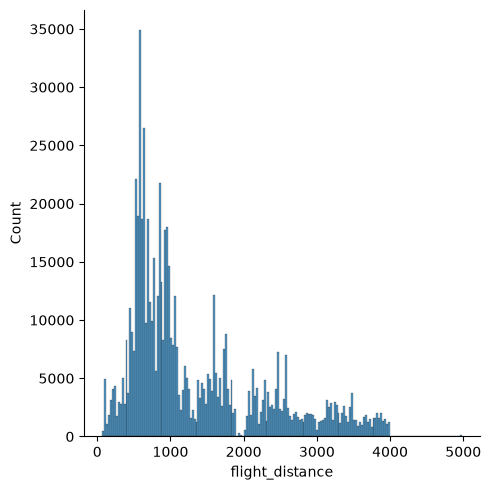

In [114]:
sns.displot(df1['flight_distance'])
plt.show()

## 1.7.2 Categorical Attributes

In [120]:
cat_attributes.apply(lambda x: x.unique().shape[0])

gender            2
customer_type     2
type_of_travel    2
class             3
dtype: int64

<Axes: xlabel='gender', ylabel='satisfaction'>

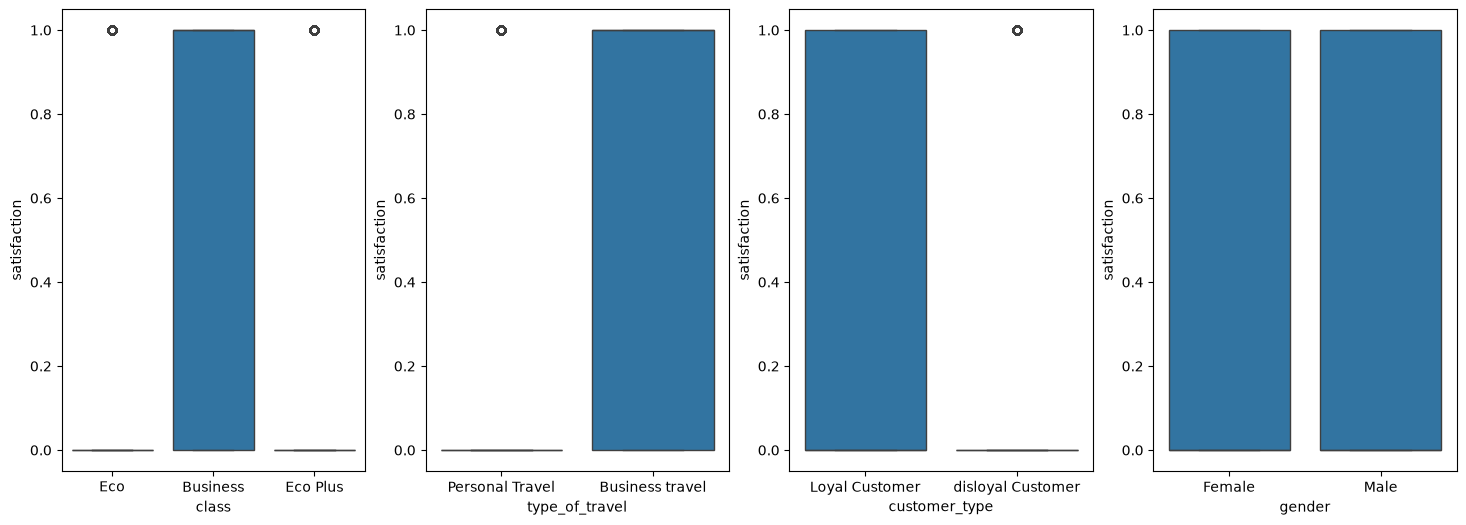

In [ ]:
#boxplot
aux1 = pd.concat([cat_attributes, df1['satisfaction']], axis=1)

plt.figure(figsize=(18, 6))
plt.subplot(1, 4, 1)
sns.boxplot(x='class', y='satisfaction', data=aux1)

plt.subplot(1, 4, 2)
sns.boxplot(x='type_of_travel', y='satisfaction', data=aux1)

plt.subplot(1, 4, 3)
sns.boxplot(x='customer_type', y='satisfaction', data=aux1)

plt.subplot(1, 4, 4)
sns.boxplot(x='gender', y='satisfaction', data=aux1)

# 2.0 FEATURE ENGINEERING

# 3.0 ANÁLISE EXPLORATÓRIA DOS DADOS - EDA

# 4.0. FEATURE SELECTION

In [131]:
df2 = df1.copy()
df3 = df2.copy()
df4 = df3.copy()

## 4.1. Filter Method

In [132]:
# Remove variáveis com variância abaixo do threshold
selector = VarianceThreshold(threshold=0.01)
X_filtered = selector.fit_transform(num_attributes)

# Verificar variância manualmente
variances = num_attributes.var()
low_var_cols = variances[variances < 0.01].index.tolist()
print("Variáveis com variância quasi-zero:", low_var_cols)

Variáveis com variância quasi-zero: []


In [133]:
#ESSE TRECHO DO CÓDIGO SÓ DÁ PARA FINALIZAR APÓS A EDA QUE VAI AJUDAR NA DETERMINAÇÃO DE VARIÁVEIS DESCARTÁVEIS

# low_variance = []# EmployeeCount e StandardHours já removidas na célula 24 (variância zero)
# low_univariate_discriminative = []
# low_correlation = []

# low_bivariate_discriminative = []
# low_bivariate_cat_discriminative = []

# auto_corr = []

## 4.2 Wrapper Method Boruta

In [134]:
df4.sample(5)

,id,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,gender,customer_type,type_of_travel,class,satisfaction
336791,336791,40,2187,4,4,4,4,5,4,5,4,4,4,4,3,5,0,0.0,Female,Loyal Customer,Business travel,Business,0
184092,184092,24,1449,3,3,4,3,3,4,3,3,3,5,4,3,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
640670,640670,36,846,4,2,2,2,5,4,4,4,5,5,4,4,3,0,0.0,Female,Loyal Customer,Business travel,Eco,1
159839,159839,48,1576,4,4,4,4,3,5,4,5,5,5,5,5,5,0,0.0,Male,Loyal Customer,Business travel,Business,1
308094,308094,22,368,2,5,2,3,1,2,1,1,4,4,4,2,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0


In [ ]:
#ENVIAR PARA BIBLIOTECAS
from sklearn import ensemble as en

#ENVIAR PARA HELPER FUNCTIONS
# Função para o boruta--- Reverter dummies para nome original
def to_original( col ):
    return col.split( '__SEP__' )[0] if '__SEP__' in col else col


# preparacao dados
X = df4.drop( columns='satisfaction' )
y = df4['satisfaction']

X_boruta = pd.get_dummies( X, prefix_sep='__SEP__', dtype=int)

# algoritmo
rf = en.RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=42)

# boruta
boruta = BorutaPy( rf, 
                   n_estimators='auto',
                   verbose=2,
                   random_state=42
).fit( X_boruta.values, y.values )

# resultados
confirmed_boruta = X_boruta.columns[boruta.support_].tolist()
tentative_boruta = X_boruta.columns[boruta.support_weak_].tolist()
rejected_boruta = X_boruta.columns[~boruta.support_ & ~boruta.support_weak_].tolist()

confirmed_boruta = sorted( set( to_original( c ) for c in confirmed_boruta ) )
tentative_boruta = sorted( set( to_original( c ) for c in tentative_boruta ) )
rejected_boruta  = sorted( set( to_original( c ) for c in rejected_boruta ) )

# Categórica só é "rejeitada" se TODAS as suas dummies foram rejeitadas.
# Se ao menos uma dummy foi confirmada/tentativa, removemos a original da lista de rejeitadas.
rejected_boruta = [ c for c in rejected_boruta
                      if c not in confirmed_boruta and c not in tentative_boruta ]

print( f'Variaveis confirmadas (originais): {confirmed_boruta}' )
print( f'Variaveis tentativas (originais):  {tentative_boruta}' )
print( f'Variaveis rejeitadas (originais):  {rejected_boruta}' )


# # --- 1) Filter Method
# rejected_columns = ( low_variance 
#                     + low_univariate_discriminative 
#                     + low_correlation 
#                     + low_bivariate_discriminative 
#                     + low_bivariate_cat_discriminative 
#                     + auto_corr
#                     + rejected_boruta )

Iteration: 	1 / 100
Confirmed: 	0
Tentative: 	27
Rejected: 	0
Iteration: 	2 / 100
Confirmed: 	0
Tentative: 	27
Rejected: 	0
Iteration: 	3 / 100
Confirmed: 	0
Tentative: 	27
Rejected: 	0
Iteration: 	4 / 100
Confirmed: 	0
Tentative: 	27
Rejected: 	0
Iteration: 	5 / 100
Confirmed: 	0
Tentative: 	27
Rejected: 	0
Iteration: 	6 / 100
Confirmed: 	0
Tentative: 	27
Rejected: 	0
Iteration: 	7 / 100
Confirmed: 	0
Tentative: 	27
Rejected: 	0
Iteration: 	8 / 100
Confirmed: 	26
Tentative: 	1
Rejected: 	0
Iteration: 	9 / 100
Confirmed: 	26
Tentative: 	1
Rejected: 	0
Iteration: 	10 / 100
Confirmed: 	26
Tentative: 	1
Rejected: 	0
Iteration: 	11 / 100
Confirmed: 	26
Tentative: 	1
Rejected: 	0
Iteration: 	12 / 100
Confirmed: 	26
Tentative: 	1
Rejected: 	0
Iteration: 	13 / 100
Confirmed: 	26
Tentative: 	1
Rejected: 	0
Iteration: 	14 / 100
Confirmed: 	26
Tentative: 	1
Rejected: 	0
